In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot  as plt
import seaborn as sns
import scipy.stats as stats

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

c:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\LENOVO\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [ ]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")


In [8]:
print(df.head(5))
print(df.columns)
hardcopy = df.copy()

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  
Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', '

In [38]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
percentages = list()
for i in range(len(crosstab)):
    percentages.append(crosstab.iloc[i][1]/crosstab.iloc[i].sum()*100)

crosstab['proportion'] = percentages

crosstab.sort_values(by="proportion", ascending=False, inplace=True)
print(crosstab)

isBestSeller                      False  True  proportion
category                                                 
Grocery                            9008   556    5.813467
Smart Home Security & Lighting       98     6    5.769231
Health & Personal Care             9017   552    5.768628
Mobile Phone Accessories            248    11    4.247104
Power & Hand Tools                 8353   306    3.533895
...                                 ...   ...         ...
CD, Disc & Tape Players            8798     0    0.000000
General Music-Making Accessories    259     0    0.000000
Snowboard Boots                    1449     0    0.000000
Boxes & Organisers                  911     0    0.000000
eBook Readers & Accessories         246     0    0.000000

[296 rows x 3 columns]


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_7788\3303225068.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  percentages.append(crosstab.iloc[i][1]/crosstab.iloc[i].sum()*100)


# Categories where best-sellers are more prevalent:

Grocery - 5.813467%

Smart Home Security & Lighting - 5.769231%

Health & Personal Care - 5.768628%

Mobile Phone Accessories - 4.247104%

Power & Hand Tools - 3.533895%

In [28]:
chisq, p, dof, ex = stats.chi2_contingency(crosstab)

print(f"chisquare value: {chisq}")
print(f"p-value: {p}")
print(f"degrees of freedom: {dof}")

chisquare value: 50603.56501614784
p-value: 0.0
degrees of freedom: 590


In [31]:
n = crosstab.to_numpy().sum() 
min_dim = min(crosstab.shape) - 1 
cramers_v = np.sqrt(chisq / (n * min_dim))

print("Cramér's V:", cramers_v)


Cramér's V: 0.10175125266461914


With a cramer V of 0.1, we expect a weak to moderate association between the variables


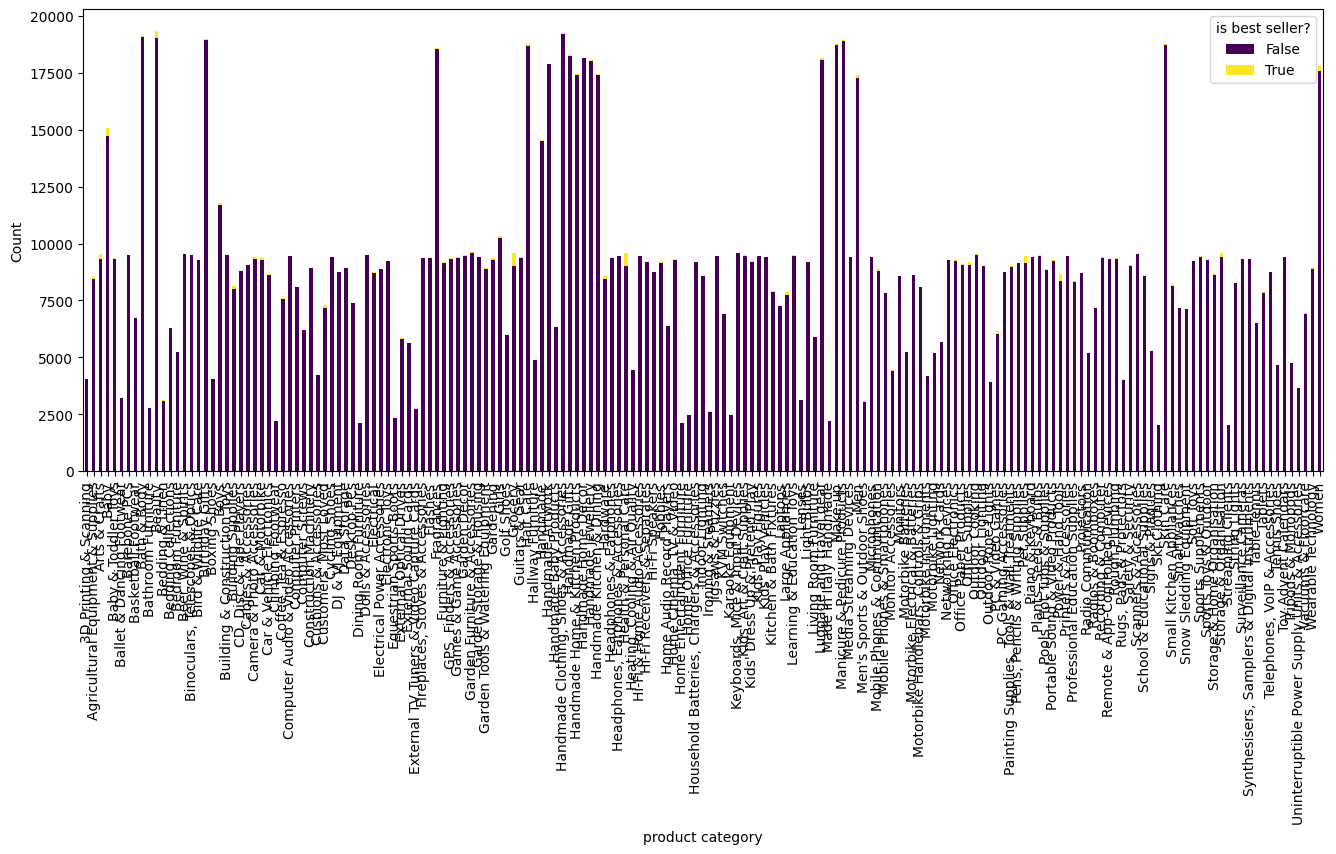

In [47]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab = crosstab[(crosstab.sum(axis=1) < 100000) & (crosstab.sum(axis=1) > 2000)]
crosstab.plot(kind='bar', stacked=True, figsize=(16, 6), colormap='viridis', )
plt.xlabel('product category')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.legend(title='is best seller?')
plt.show()

In [48]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

# Calculate the IQR
IQR = Q3 - Q1

# Define outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the DataFrame to remove outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]


<Axes: xlabel='price', ylabel='Count'>

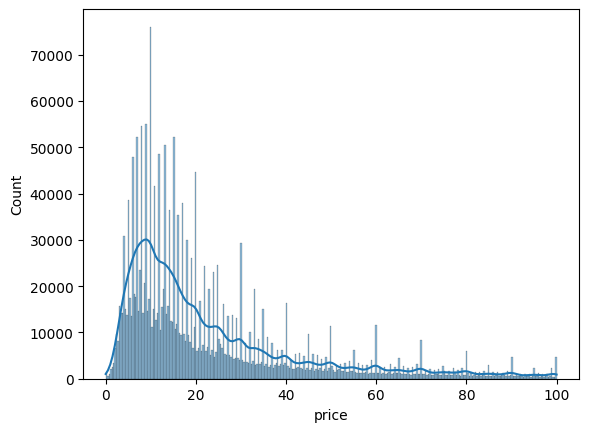

In [49]:
sns.histplot(df_no_outliers['price'], kde=True)

                   category   price
0               Desktop PCs  74.000
1              Boxing Shoes  69.790
2                   Tablets  69.000
3            Graphics Cards  68.540
4              Motherboards  67.920
5    Made in Italy Handmade  64.000
6            Digital Frames  63.900
7         Streaming Clients  62.680
8                Golf Shoes  62.390
9               Ski Helmets  61.330
10             Hockey Shoes  57.800
11            Cycling Shoes  55.990
12    Home Office Furniture  55.620
13             Skiing Poles  55.230
14           Computer Cases  54.990
15      Motorbike Batteries  54.200
16    Dining Room Furniture  53.000
17  Motorbike Drive & Gears  52.600
18              3D Printers  52.195
19       Downhill Ski Boots  51.090


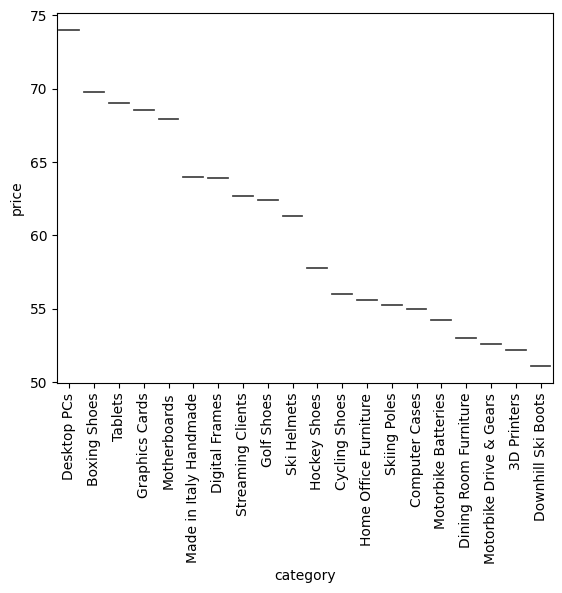

In [87]:
# creating a violing plot with the categories and median prices of top 20 median price

violin_df = df_no_outliers.groupby('category')['price'].median().nlargest(20).reset_index()

print(violin_df)

violin_plot = sns.violinplot(x='category', y='price', data=violin_df)
plt.xticks(rotation=90)
plt.show()

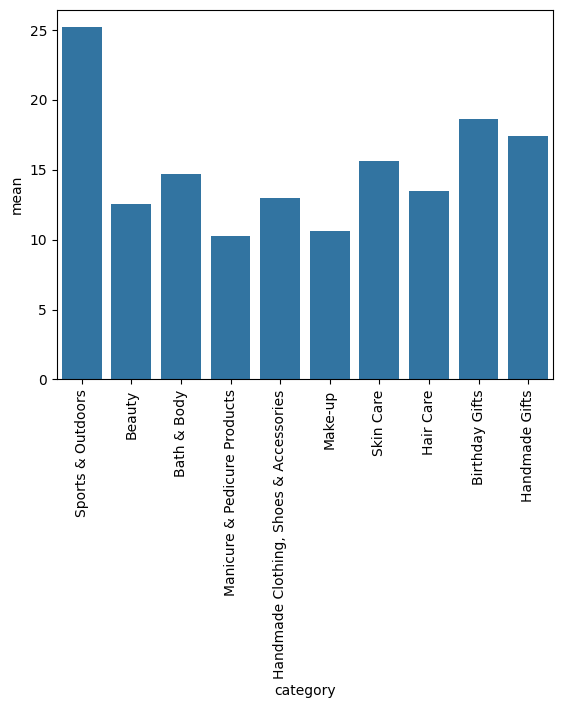

In [100]:
bar_df = df_no_outliers.groupby('category')['price'].count().nlargest(10).reset_index()

means = list()
for cat in bar_df['category']:
    means.append(df_no_outliers.groupby('category')['price'].mean()[cat])

bar_df['mean'] = means

barplot = sns.barplot(x='category', y='mean', data=bar_df)
plot = plt.xticks(rotation=90)
plt.show()

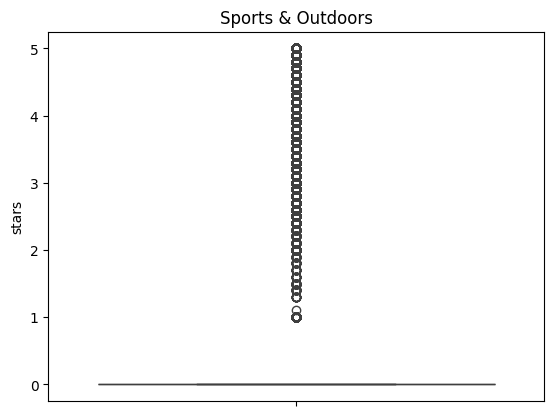

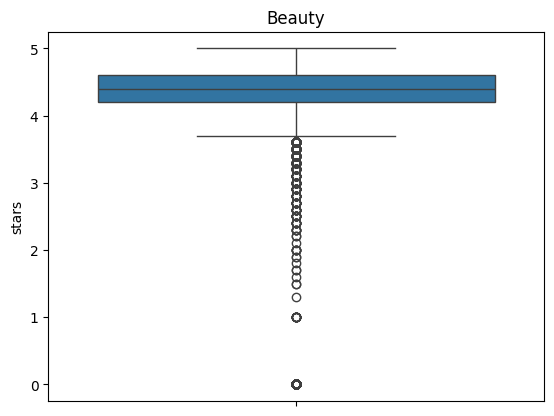

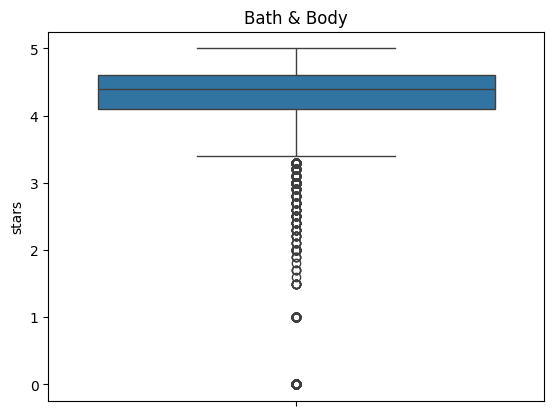

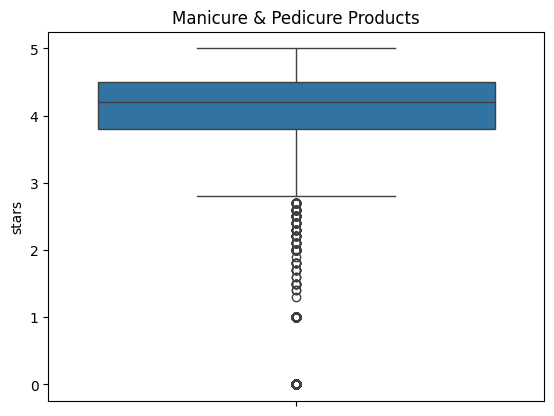

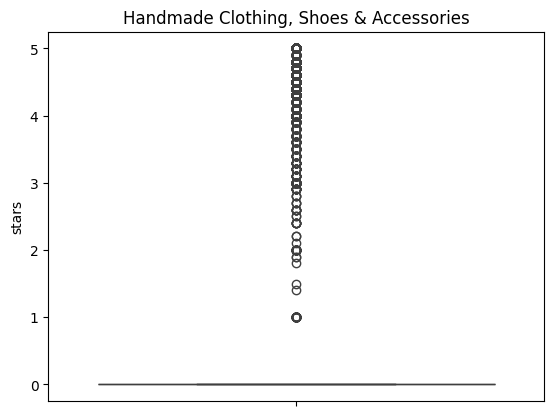

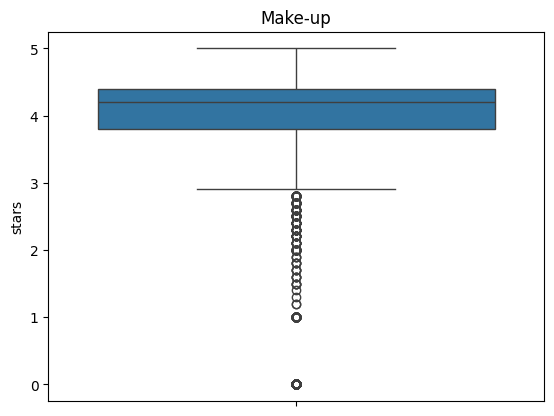

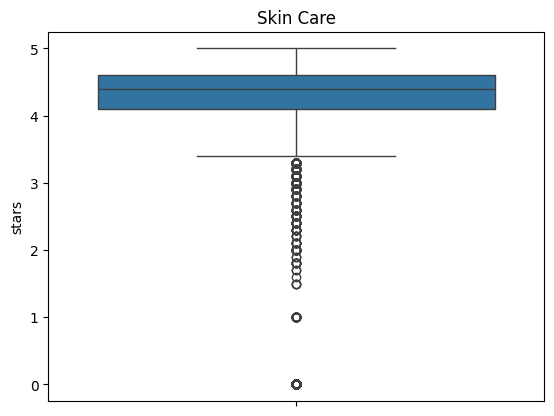

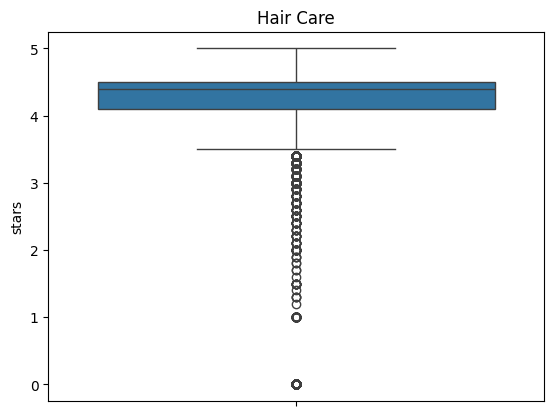

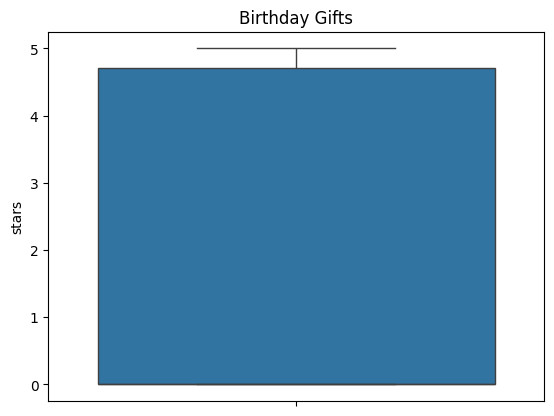

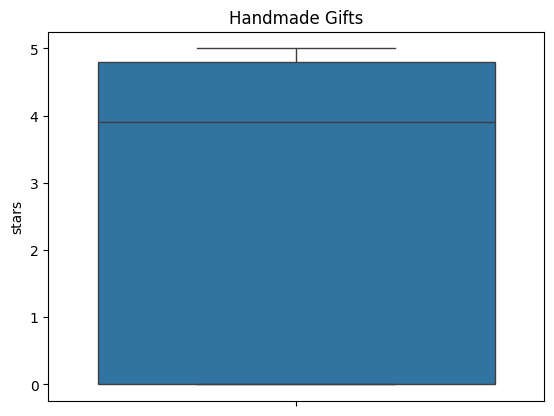

In [105]:
box_df = df_no_outliers.groupby('category')['stars'].count().nlargest(10).reset_index()

for cat in box_df['category']:
    sns.boxplot(df_no_outliers[df_no_outliers['category'] == cat]['stars'])
    plt.title(cat)
    plt.show()
    

